### Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

### Carga de dataset

In [3]:
data = pd.read_excel('Desktop/Dry_Bean_Dataset.xlsx')

In [4]:
data.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [5]:
print(data.shape)
print(data.columns.tolist())
print(data.isnull().sum().sum())

(13611, 17)
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']
0


In [6]:
# Variables predictoras
X = data.drop('Class', axis=1)

# Variable objetivo
y = data['Class']

print("Cantidad de variables predictoras:", X.shape[1])
print("Cantidad de registros:", X.shape[0])

print("\nVariedades de porotos:")
print(y.value_counts())

Cantidad de variables predictoras: 16
Cantidad de registros: 13611

Variedades de porotos:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


### Division de datos entrenamiento y prueba

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (10888, 16)
Datos de prueba: (2723, 16)


### Entrenar arbol de desicion

In [10]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = DecisionTreeClassifier(
    random_state=42
)

modelo_arbol.fit(X_train, y_train)

predicciones_arbol = modelo_arbol.predict(X_test)

print("Árbol de Decisión entrenado ")

Árbol de Decisión entrenado 


### Evaluacion

In [11]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_arbol = accuracy_score(
    y_test,
    predicciones_arbol
)

print("Accuracy del Árbol de Decisión:",
      round(accuracy_arbol, 4))

print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_arbol))

Accuracy del Árbol de Decisión: 0.8917

Informe de clasificación:
              precision    recall  f1-score   support

    BARBUNYA       0.89      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92      0.92       326
    DERMASON       0.88      0.89      0.88       709
       HOROZ       0.94      0.92      0.93       386
       SEKER       0.91      0.94      0.92       406
        SIRA       0.83      0.79      0.81       527

    accuracy                           0.89      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.89      0.89      0.89      2723



### Grafico de arbol

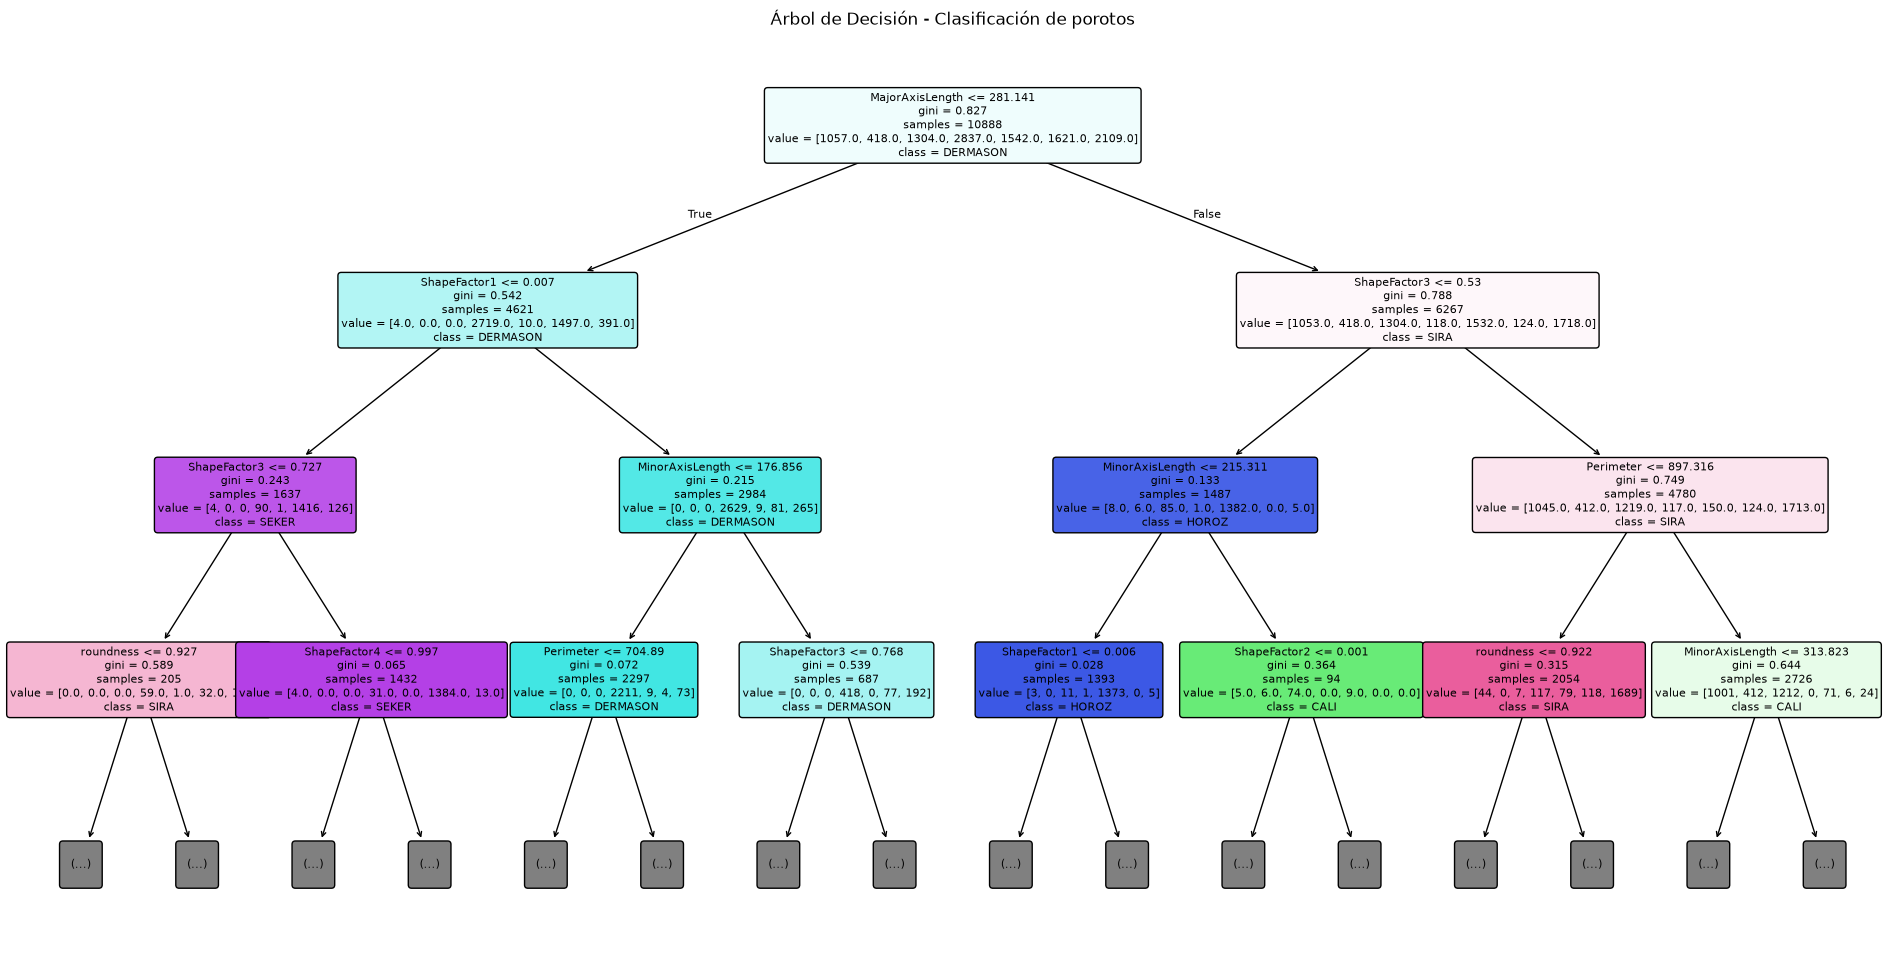

In [14]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    modelo_arbol,
    feature_names=X.columns,
    class_names=modelo_arbol.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Árbol de Decisión - Clasificación de porotos")
plt.show()

### Matriz de confusion

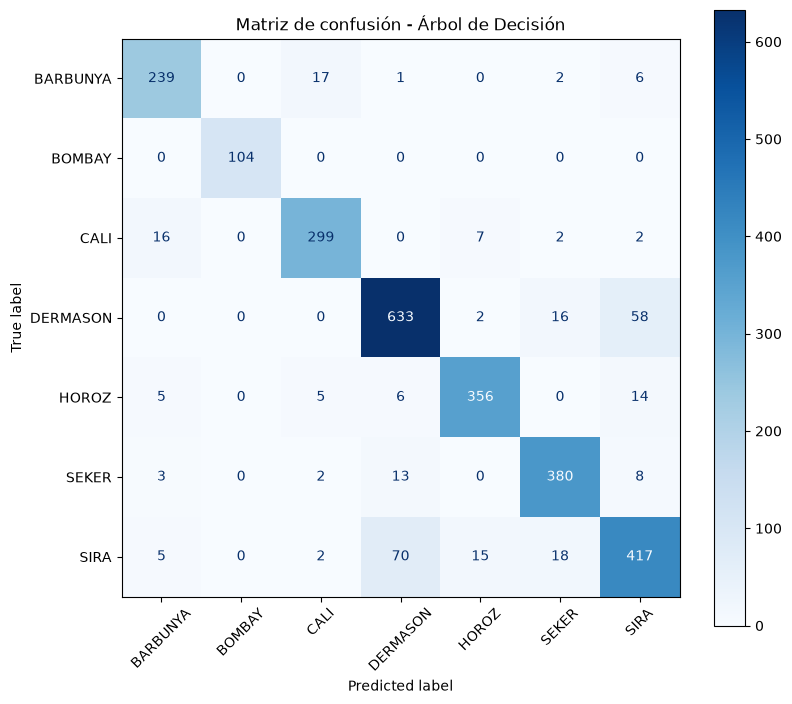

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz de confusión
matriz = confusion_matrix(
    y_test,
    predicciones_arbol,
    labels=modelo_arbol.classes_
)

# Graficar la matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo_arbol.classes_
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.title("Matriz de confusión - Árbol de Decisión")
plt.xticks(rotation=45)
plt.show()

### MODELO K-NN

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Normalizar las variables
escalador = StandardScaler()

X_train_scaled = escalador.fit_transform(X_train)
X_test_scaled = escalador.transform(X_test)

# Crear y entrenar el modelo K-NN
modelo_knn = KNeighborsClassifier(n_neighbors=5)

modelo_knn.fit(X_train_scaled, y_train)

# Realizar predicciones
predicciones_knn = modelo_knn.predict(X_test_scaled)

print("Modelo K-NN entrenado correctamente.")

Modelo K-NN entrenado correctamente.


### Evaluacion 

In [17]:
accuracy_knn = accuracy_score(y_test, predicciones_knn)

print("Accuracy de K-NN:", round(accuracy_knn, 4))

print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_knn))

Accuracy de K-NN: 0.9166

Informe de clasificación:
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



### Matriz de confusion

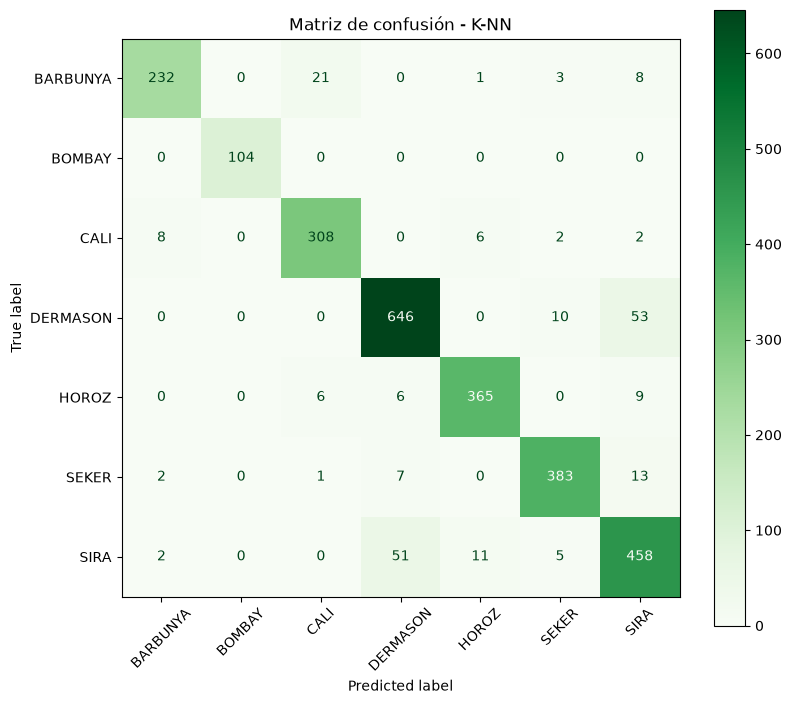

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz_knn = confusion_matrix(
    y_test,
    predicciones_knn,
    labels=modelo_arbol.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_knn,
    display_labels=modelo_arbol.classes_
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(cmap="Greens", values_format="d", ax=ax)

plt.title("Matriz de confusión - K-NN")
plt.xticks(rotation=45)
plt.show()

### valores de k

In [24]:

from sklearn.metrics import precision_score, recall_score, f1_score


In [25]:

resultados_k = []

for k in [1, 3, 5, 7, 11, 21, 31]:

    modelo = KNeighborsClassifier(n_neighbors=k)

    modelo.fit(X_train_scaled, y_train)
    pred = modelo.predict(X_test_scaled)

    resultados_k.append({
        'K': k,
        'Accuracy': accuracy_score(y_test, pred),
        'Precisión': precision_score(
            y_test, pred, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred, average='macro', zero_division=0
        ),
        'F1-score': f1_score(
            y_test, pred, average='macro', zero_division=0
        )
    })

tabla_k = pd.DataFrame(resultados_k).set_index('K')

display(tabla_k.round(4))


,Accuracy,Precisión,Recall,F1-score
K,,,,
1,0.8986,0.9149,0.9135,0.9141
3,0.9152,0.9298,0.9274,0.9285
5,0.9166,0.9320,0.9271,0.9293
7,0.9137,0.9290,0.9245,0.9265
11,0.9185,0.9342,0.9287,0.9310
21,0.9188,0.9348,0.9294,0.9316
31,0.9210,0.9357,0.9307,0.9328


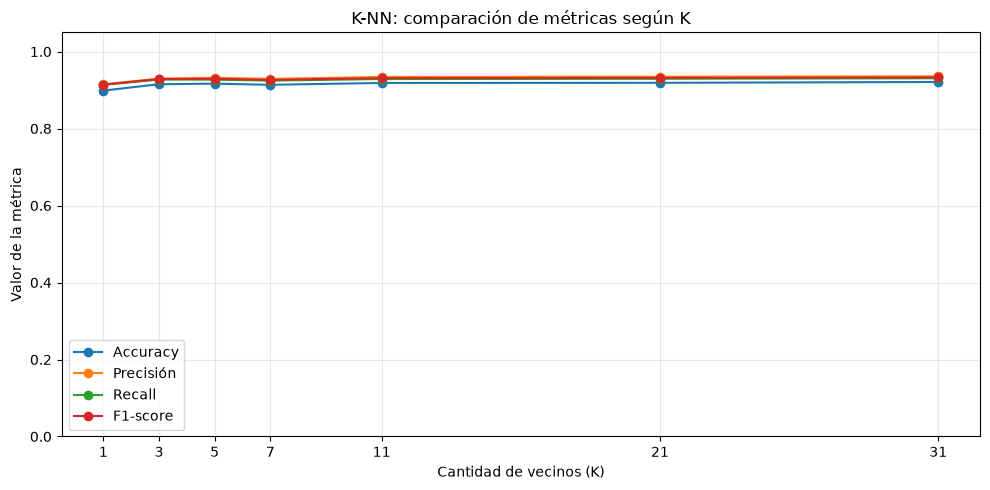

In [26]:

tabla_k.plot(
    marker='o',
    figsize=(10, 5),
    ylim=(0, 1.05)
)

plt.title('K-NN: comparación de métricas según K')
plt.xlabel('Cantidad de vecinos (K)')
plt.ylabel('Valor de la métrica')
plt.xticks(tabla_k.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Grafico K-NN

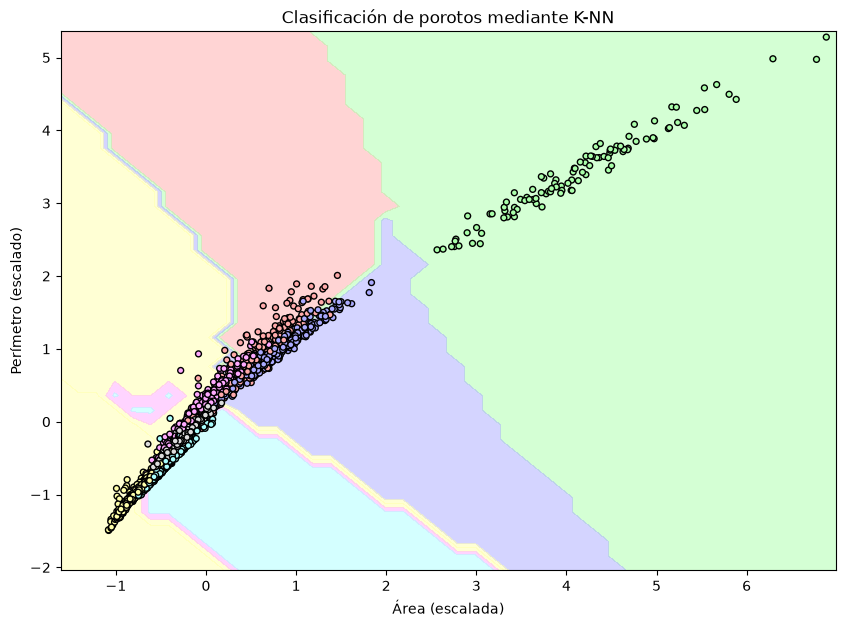

In [22]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Elegimos dos variables para poder graficarlas
variables = ["Area", "Perimeter"]

X_grafico = X[variables]

# Separamos los datos de entrenamiento y prueba
X_train_grafico = X_train[variables]
X_test_grafico = X_test[variables]

# Escalamos las variables
escalador_grafico = StandardScaler()
X_train_escalado = escalador_grafico.fit_transform(X_train_grafico)
X_test_escalado = escalador_grafico.transform(X_test_grafico)

# Entrenamos K-NN con estas dos variables
knn_grafico = KNeighborsClassifier(n_neighbors=5)
knn_grafico.fit(X_train_escalado, y_train)

# Creamos el mallado con paso de 0.2
x_min, x_max = X_train_escalado[:, 0].min() - 0.5, X_train_escalado[:, 0].max() + 0.5
y_min, y_max = X_train_escalado[:, 1].min() - 0.5, X_train_escalado[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.2),
    np.arange(y_min, y_max, 0.2)
)

# Clasificamos cada punto del mallado
Z = knn_grafico.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Creamos un mapa de colores
colores = ListedColormap([
    "#FFAAAA", "#AAFFAA", "#AAAAFF",
    "#FFFFAA", "#FFAAFF", "#AAFFFF", "#DDDDDD"
])

# Convertimos las clases a números para representarlas
clases = knn_grafico.classes_
Z_num = np.searchsorted(clases, Z)

plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z_num, cmap=colores, alpha=0.5)

# Mostramos las muestras reales de prueba
y_num = np.searchsorted(clases, y_test)
plt.scatter(
    X_test_escalado[:, 0],
    X_test_escalado[:, 1],
    c=y_num,
    cmap=colores,
    edgecolor="black",
    s=18
)

plt.xlabel("Área (escalada)")
plt.ylabel("Perímetro (escalado)")
plt.title("Clasificación de porotos mediante K-NN")
plt.show()


In [23]:
comparacion = pd.DataFrame({
    "Modelo": ["Árbol de Decisión", "K-NN"],
    "Accuracy": [accuracy_arbol, accuracy_knn]
})

display(comparacion)

,Modelo,Accuracy
0,Árbol de Decisión,0.891664
1,K-NN,0.916636
